# 2.1 Exploration : Dataset 1

165 images de documents (Kaggle), 3 classes : `email`, `resume`, `scientific_publication`.

Les fonctions utilisées sont dans [outils_2.py](outils_2.py).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

from outils_2 import list_images, add_visual_metrics, show_mosaic, values_by_class

DOSSIER = "../data/document-classification-dataset_1"

## Chargement des images et calcul des 6 métriques visuelles

In [2]:
df = list_images(DOSSIER)
df = add_visual_metrics(df)
print(len(df), "images")
df.head()

  0%|          | 0/165 [00:00<?, ?it/s]

 22%|██▏       | 37/165 [00:00<00:00, 366.39it/s]

 45%|████▌     | 75/165 [00:00<00:00, 368.30it/s]

 68%|██████▊   | 113/165 [00:00<00:00, 372.64it/s]

 99%|█████████▉| 163/165 [00:00<00:00, 420.17it/s]

100%|██████████| 165/165 [00:00<00:00, 402.27it/s]

165 images


,filepath,label,width,height,brightness,contrast,dark_ratio,aspect_ratio
0,../data/document-classification-dataset_1/resu...,resume,754,1000,234.411835,56.726704,0.079191,0.754
1,../data/document-classification-dataset_1/resu...,resume,754,1000,240.997070,49.562576,0.053436,0.754
2,../data/document-classification-dataset_1/resu...,resume,754,1000,241.733978,47.606915,0.051590,0.754
3,../data/document-classification-dataset_1/resu...,resume,754,1000,227.461349,65.343468,0.103828,0.754
4,../data/document-classification-dataset_1/resu...,resume,754,1000,237.165939,50.567986,0.067845,0.754


## Fig. 1 : Répartition des classes

Test du Chi² : les classes ont-elles le même effectif ?

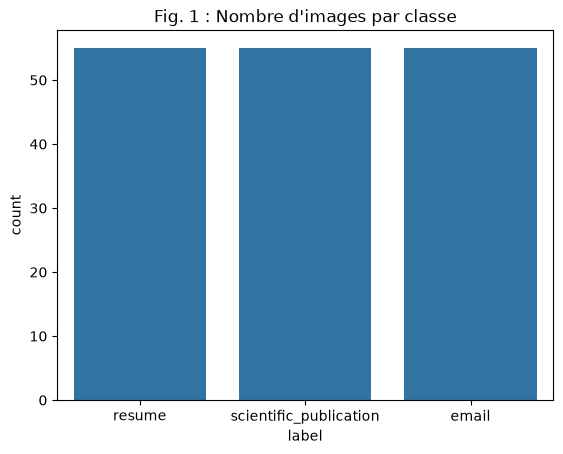

Chi² = 0.00   p-value = 1.0000


In [3]:
sns.countplot(data=df, x="label")
plt.title("Fig. 1 : Nombre d'images par classe")
plt.show()

chi2, p = stats.chisquare(df["label"].value_counts())
print(f"Chi² = {chi2:.2f}   p-value = {p:.4f}")

## Fig. 2 : Exemples d'images par classe

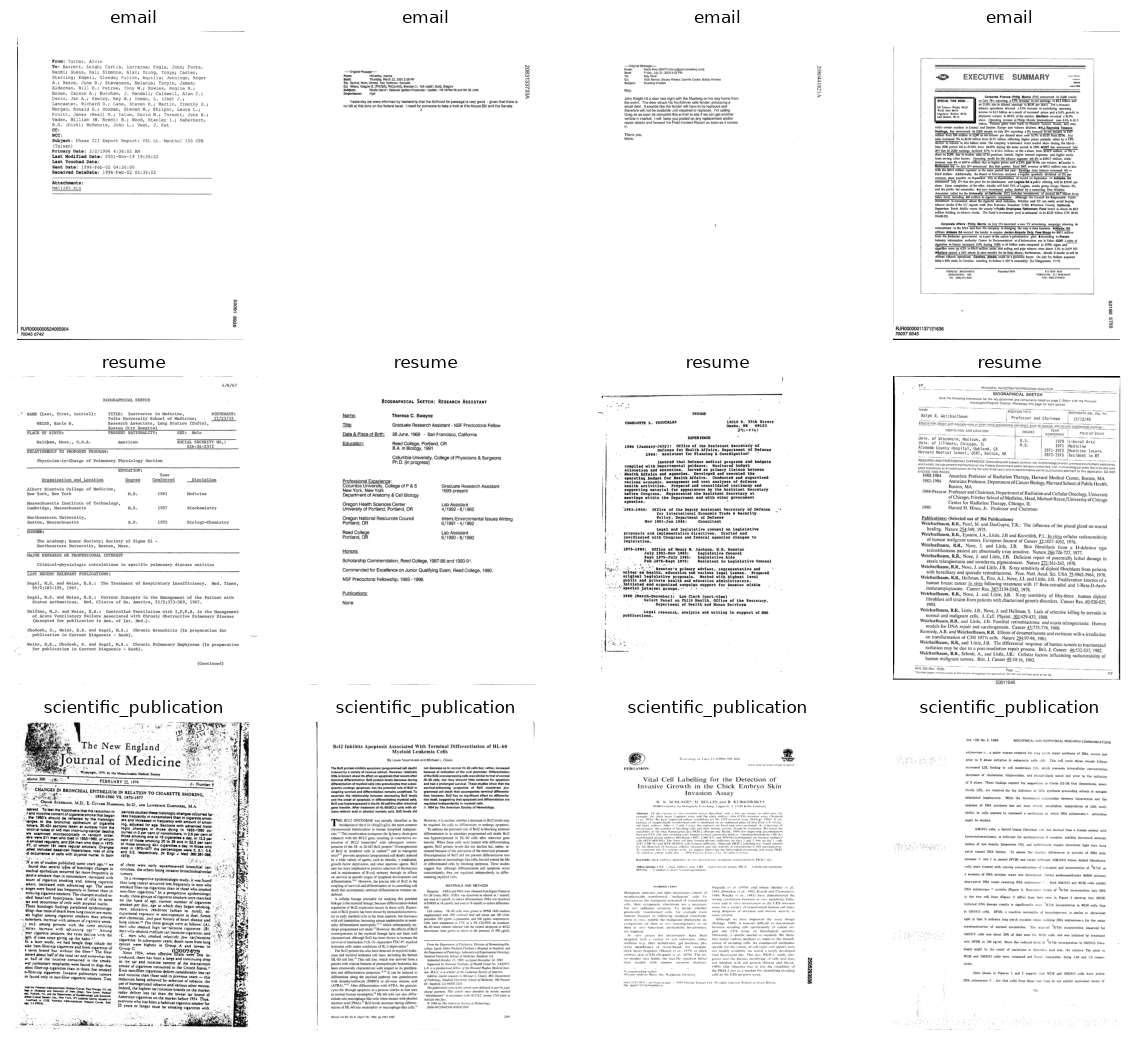

In [4]:
show_mosaic(df)

## Fig. 3 : Résolution des images

ANOVA : la largeur moyenne change-t-elle selon la classe ?

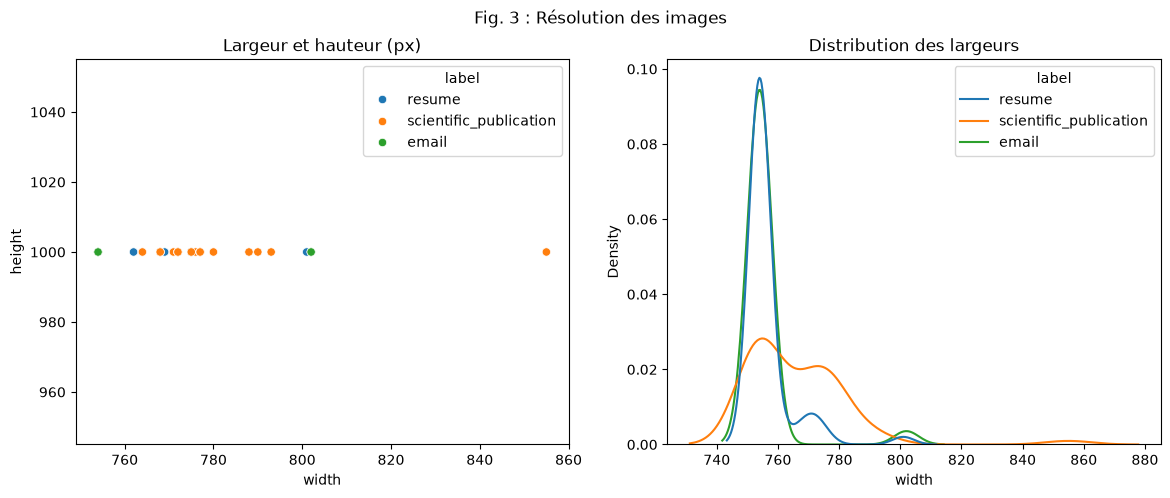

ANOVA largeurs : F = 12.71   p-value = 0.0000
Largeur : min = 754 px, max = 855 px


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=df, x="width", y="height", hue="label", ax=axes[0])
axes[0].set_title("Largeur et hauteur (px)")
sns.kdeplot(data=df, x="width", hue="label", common_norm=False, ax=axes[1])
axes[1].set_title("Distribution des largeurs")
plt.suptitle("Fig. 3 : Résolution des images")
plt.show()

f, p = stats.f_oneway(*values_by_class(df, "width"))
print(f"ANOVA largeurs : F = {f:.2f}   p-value = {p:.4f}")
print(f"Largeur : min = {df['width'].min()} px, max = {df['width'].max()} px")

## Fig. 4 : Qualité des scans : luminosité et contraste

Kruskal-Wallis : la luminosité change-t-elle selon la classe ?

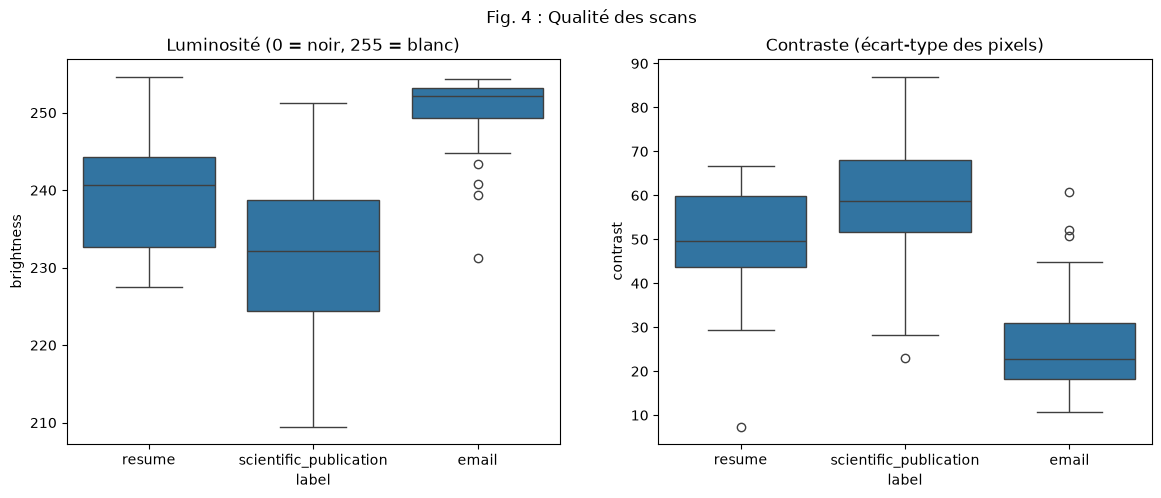

Kruskal-Wallis luminosité : H = 95.90   p-value = 0.0000


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, x="label", y="brightness", ax=axes[0])
axes[0].set_title("Luminosité (0 = noir, 255 = blanc)")
sns.boxplot(data=df, x="label", y="contrast", ax=axes[1])
axes[1].set_title("Contraste (écart-type des pixels)")
plt.suptitle("Fig. 4 : Qualité des scans")
plt.show()

h, p = stats.kruskal(*values_by_class(df, "brightness"))
print(f"Kruskal-Wallis luminosité : H = {h:.2f}   p-value = {p:.4f}")

## Fig. 5 : Densité d'encre et format

Mann-Whitney : on compare la classe la moins dense en encre à la plus dense.

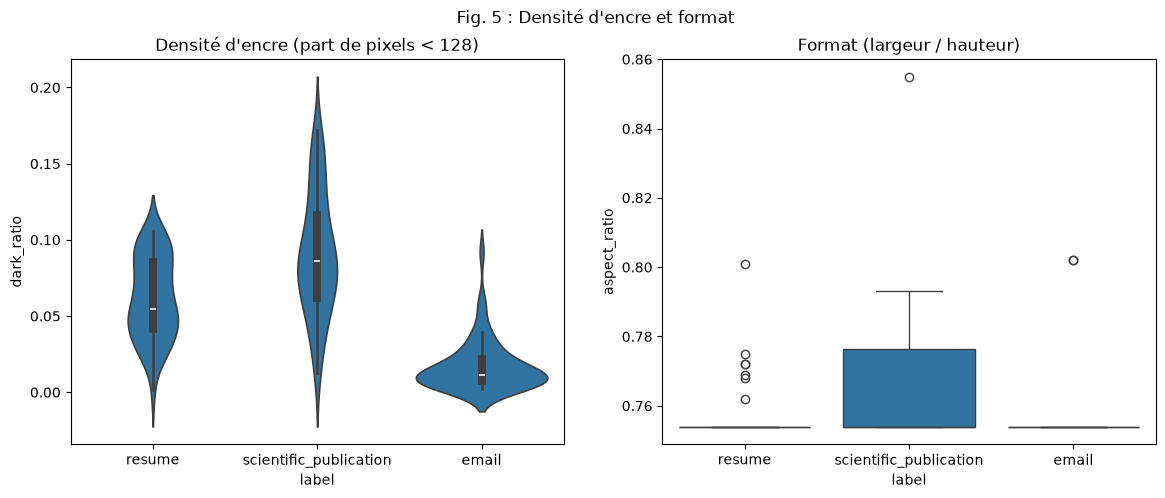

Mann-Whitney email vs scientific_publication : U = 109   p-value = 0.0000


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.violinplot(data=df, x="label", y="dark_ratio", ax=axes[0])
axes[0].set_title("Densité d'encre (part de pixels < 128)")
sns.boxplot(data=df, x="label", y="aspect_ratio", ax=axes[1])
axes[1].set_title("Format (largeur / hauteur)")
plt.suptitle("Fig. 5 : Densité d'encre et format")
plt.show()

medianes = df.groupby("label")["dark_ratio"].median().sort_values()
moins_dense, plus_dense = medianes.index[0], medianes.index[-1]
u, p = stats.mannwhitneyu(df.loc[df["label"] == moins_dense, "dark_ratio"],
                          df.loc[df["label"] == plus_dense, "dark_ratio"])
print(f"Mann-Whitney {moins_dense} vs {plus_dense} : U = {u:.0f}   p-value = {p:.4f}")

## Fig. 6 : Séparabilité des classes : PCA et corrélations

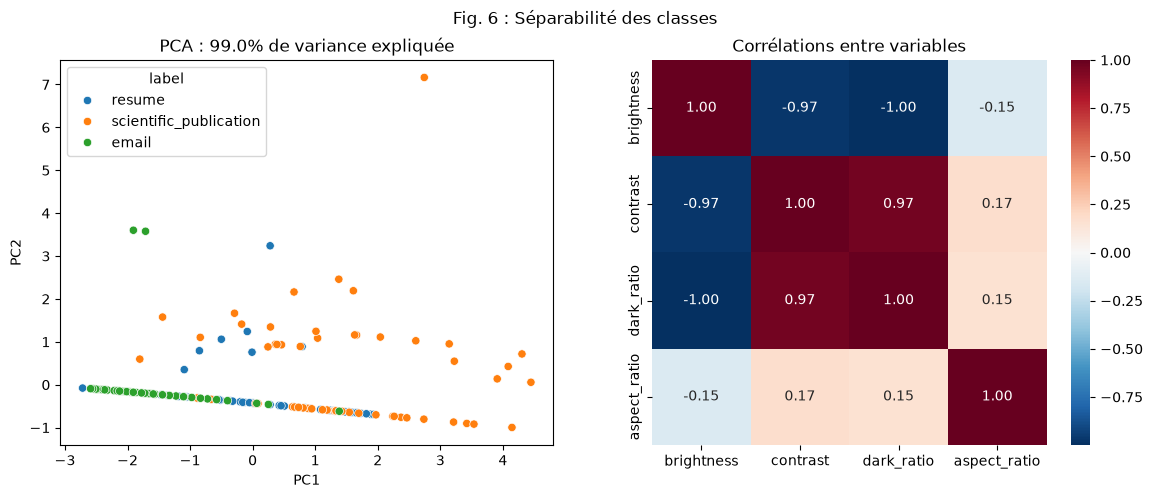

,PC1,PC2
brightness,-0.574,0.089
contrast,0.569,-0.057
dark_ratio,0.574,-0.085
aspect_ratio,0.134,0.991


In [8]:
VARIABLES = ["brightness", "contrast", "dark_ratio", "aspect_ratio"]
X = StandardScaler().fit_transform(df[VARIABLES])
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=df["label"], ax=axes[0])
axes[0].set_title(f"PCA : {pca.explained_variance_ratio_.sum():.1%} de variance expliquée")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")
sns.heatmap(df[VARIABLES].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[1])
axes[1].set_title("Corrélations entre variables")
plt.suptitle("Fig. 6 : Séparabilité des classes")
plt.show()

# poids de chaque variable sur les 2 axes
pd.DataFrame(pca.components_.T, index=VARIABLES, columns=["PC1", "PC2"]).round(3)

## Synthèse

ANOVA : la densité d'encre change-t-elle selon la classe ? Puis la médiane des 6 métriques par classe.

In [9]:
f, p = stats.f_oneway(*values_by_class(df, "dark_ratio"))
print(f"ANOVA densité d'encre : F = {f:.2f}   p-value = {p:.4f}")
print("Images très sombres (luminosité < 50) :", (df["brightness"] < 50).sum())

METRIQUES = ["width", "height", "brightness", "contrast", "dark_ratio", "aspect_ratio"]
df.groupby("label")[METRIQUES].median().round(3)

ANOVA densité d'encre : F = 89.08   p-value = 0.0000
Images très sombres (luminosité < 50) : 0


,width,height,brightness,contrast,dark_ratio,aspect_ratio
label,,,,,,
email,754.0,1000.0,252.100006,22.847000,0.011,0.754
resume,754.0,1000.0,240.695999,49.563000,0.055,0.754
scientific_publication,754.0,1000.0,232.179001,58.606998,0.086,0.754
